# Calibration de Modèle de Heston

## Intro

In [35]:
import pandas as pd
import nbformat
import plotly.express as px
import numpy as np
import scipy.optimize as opt
from scipy.stats import norm
import matplotlib.pyplot as plt

In [2]:
# Spot Amazon 195

In [3]:
calls_df = pd.read_csv("calls_data.csv")
puts_df = pd.read_csv("puts_data.csv")

In [4]:
calls_df["Price"] = (calls_df["Bid"] + calls_df["Ask"])/2
calls_df = calls_df.iloc[:,-3:]

In [5]:
fig = px.scatter_3d(calls_df, x="Strike", y="Maturity", z="Price",
                     color="Price", color_continuous_scale="viridis")

fig.update_layout(title="Visualisation interactive des prix des options",
                  scene=dict(xaxis_title="Strike", 
                             yaxis_title="Maturity (jours)", 
                             zaxis_title="Price"))

fig.show()


## Modèle Black-Scholes

Le modèle de Black-Scholes est un outil fondamental dans la tarification des options. Développé par Fischer Black, Myron Scholes et Robert Merton, ce modèle fournit une formule pour estimer le prix d'une option européenne. Selon ce modèle, le prix de l'option dépend de cinq paramètres principaux : le prix actuel de l'actif sous-jacent, le prix d'exercice de l'option, le temps jusqu'à l'expiration, le taux d'intérêt sans risque et la volatilité de l'actif sous-jacent.

Une hypothèse clée du modèle Black-Scholes est que la volatilité de l'actif sous-jacent est constante sur la durée de vie de l'option. Bien que cette hypothèse simplifie le modèle, elle limite sa précision, surtout pour les options à long terme où la volatilité peut varier considérablement.

L'équation de Black-Scholes pour une option d'achat (call) européenne est donnée par :

$$C(S, t) = S_t \cdot N(d_1) - K \cdot e^{-r(T-t)} \cdot N(d_2)$$

où :

- $C(S, t)$ est le prix de l'option d'achat.

- $S_t$ est le prix actuel de l'actif sous-jacent.

- $K$ est le prix d'exercice de l'option.

- $T$ est le temps jusqu'à l'expiration de l'option.

- $r$ est le taux d'intérêt sans risque.

- $N(.)$ est la fonction de distribution cumulative de la loi normale.

- $d_1 = \frac{\ln(\frac{S_t}{K}) + (r + \frac{\sigma^2}{2})(T-t)}{\sigma \sqrt{T-t}}$

- $d_2 = d_1 - \sigma \sqrt{T-t}$

- $\sigma$ est la volatilité du prix de l'actif sous-jacent.

In [6]:
# Modèle de Black-Scholes pour le prix d'un Call
def black_scholes_call(S, K, T, r, sigma):
    """ Calcule le prix d'un call européen selon Black-Scholes """
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

# Fonction pour calculer la volatilité implicite
def implied_volatility(price, S, K, T, r):
    """ Trouve la volatilité implicite qui donne le prix observé de l'option """
    try:
        func = lambda sigma: black_scholes_call(S, K, T, r, sigma) - price
        return opt.brentq(func, 1e-6, 5)  # Recherche entre 0.000001 et 500%
    except ValueError:
        return np.nan  # Retourne NaN si pas de solution trouvée

# Paramètres de marché (à adapter selon tes données)
S = 195  # Prix du sous-jacent (ex: action)
r = 0.05  # Taux d'intérêt sans risque (5%)

# Calcul de la volatilité implicite pour chaque option
calls_df["Implied Volatility"] = calls_df.apply(
    lambda row: implied_volatility(row["Price"], S, row["Strike"], row["Maturity"] / 365, r),
    axis=1
)


In [7]:
fig = px.scatter_3d(calls_df, x="Strike", y="Maturity", z="Implied Volatility",
                     color="Price", color_continuous_scale="viridis")

fig.update_layout(title="Visualisation interactive des volatilités implicite",
                  scene=dict(xaxis_title="Strike", 
                             yaxis_title="Maturity (jours)", 
                             zaxis_title="Price"))

fig.show()


## Modèle de Heston

Le modèle Heston, proposé par Steven Heston, est une amélioration significative par rapport au modèle de Black-Scholes, surtout en ce qui concerne la modélisation de la volatilité. Ce modèle introduit la notion de volatilité stochastique, où la volatilité d'un actif est elle-même un processus aléatoire. 

Le modèle Heston décrit la dynamique du prix de l'actif sous-jacent et sa volatilité à l'aide de deux équations différentielles stochastiques. Une caractéristique importante du modèle Heston est sa capacité à capturer des phénomènes de marché tels que le "Volatility Smile", où la volatilité implicite varie avec le prix d'exercice de l'option, ce que le modèle Black-Scholes ne peut pas expliquer.

Dans le modèle Heston, la dynamique du prix de l'actif $S_t$ et la variance stochastique $v_t$ sont décrites par les équations différentielles stochastiques suivantes :

$$dS_t = \mu S_t dt + \sqrt{v_t} S_t dW_{t}^{1}$$

$$dv_t = \kappa (\theta - v_t) dt + \xi \sqrt{v_t} dW_{t}^{2}$$

où :

- $S_t$ est la valeur de l'actif au moment $t$.

- $\mu$ est le taux de rendement attendu de l'actif.

- $v_t$ est la variance instantanée (volatilité carrée) de l'actif.

- $\kappa$ est le taux de retour à la moyenne de la variance.

- $\theta$ est la variance à long terme.

- $\xi$ est la volatilité de la volatilité.

- $W_{t}^{1}$ est le processus stochastique de Wiener régissant le processus $S_t$.
  
- $W_{t}^{2}$ est le processus stochastique de Wiener régissant le processus$v_t$.

- La corrélation entre $W_{t}^{1}$ et $W_{t}^{2}$ est $\rho$.

Ces équations capturent la nature dynamique de la volatilité dans le modèle Heston, permettant une modélisation plus précise du prix des options, en particulier pour les marchés où la volatilité n'est pas constante.

## Pricer Monte Carlo

In [ ]:
import numpy as np

# Heston model simulation for Monte Carlo pricing
def heston_monte_carlo(S0, K, T, r, v0, kappa, theta, sigma, rho, num_simulations=10000, num_steps=100):
    """
    Monte Carlo simulation for European option pricing using the Heston model.
    
    Parameters:
    S0          : Initial spot price
    K           : Strike price
    T           : Time to maturity
    r           : Risk-free rate
    v0          : Initial volatility
    kappa       : Rate of mean reversion
    theta       : Long-term volatility
    sigma       : Volatility of volatility
    rho         : Correlation between asset price and volatility
    num_simulations : Number of simulations
    num_steps   : Number of time steps in the simulation

    Returns:
    option_price : Price of the option
    """
    
    dt = T / num_steps  # Time step
    discount_factor = np.exp(-r * T)  # Discount factor for payoff
    
    # Simulating asset paths
    option_prices = []

    for _ in range(num_simulations):
        S = S0  # Initial spot price
        v = v0  # Initial volatility
        
        # Simulate the path for the asset price and volatility
        for _ in range(num_steps):
            # Generate correlated random variables for the price and volatility process
            dW1 = np.random.normal(0, np.sqrt(dt))  # Asset price Wiener process
            dW2 = np.random.normal(0, np.sqrt(dt))  # Volatility process Wiener process

            dW2 = rho * dW1 + np.sqrt(1 - rho**2) * dW2  # Correlated random variables
            
            # Heston model SDEs
            S = S * np.exp((r - 0.5 * v) * dt + np.sqrt(v) * dW1)  # Stock price update
            v = v + kappa * (theta - v) * dt + sigma * np.sqrt(v) * dW2  # Volatility update

            # Ensure that the volatility remains non-negative
            v = max(v, 0)

        # Calculate the payoff for the option at maturity
        payoff = max(S - K, 0)  # Call option payoff
        option_prices.append(payoff)

    # Discount the average payoff to present value
    option_price = discount_factor * np.mean(option_prices)

    return option_price


S = 100       # Spot price
K = 100       # Strike price
T = 1.0       # Maturity (in years)
r = 0.05      # Risk-free rate
v0 = 0.04     # Initial volatility
kappa = 2.0   # Speed of mean reversion
theta = 0.04  # Long-term variance
sigma = 0.3   # Volatility of volatility
rho = -0.7    # Correlation between asset price and volatility

# Price the European call option using Monte Carlo simulation
mc_call_price = heston_monte_carlo(S, K, T, r, v0, kappa, theta, sigma, rho, num_simulations=20000, num_steps=100)
print(f"Monte Carlo Call Option Price: {mc_call_price:.4f}")


Monte Carlo Call Option Price: 10.4431


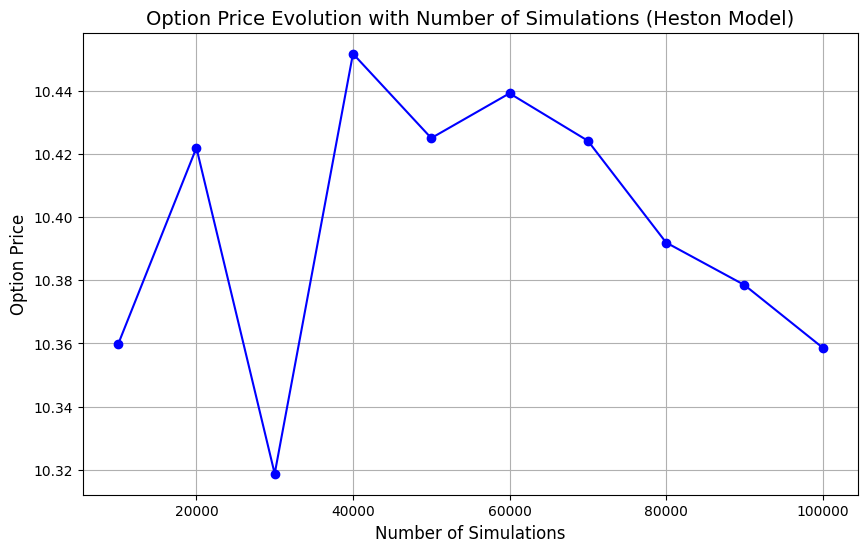

In [38]:
# Reduce the number of simulations and steps for faster computation
simulation_counts = np.linspace(10000, 100000, 10, dtype=int)  # Reduce the range and number of simulations
option_prices = []

for num_simulations in simulation_counts:
    mc_call_price = heston_monte_carlo(S, K, T, r, v0, kappa, theta, sigma, rho, num_simulations=num_simulations, num_steps=50)  # Reduce num_steps
    option_prices.append(mc_call_price)

# Plotting the result
plt.figure(figsize=(10, 6))
plt.plot(simulation_counts, option_prices, marker='o', linestyle='-', color='b')
plt.title('Option Price Evolution with Number of Simulations (Heston Model)', fontsize=14)
plt.xlabel('Number of Simulations', fontsize=12)
plt.ylabel('Option Price', fontsize=12)
plt.grid(True)
plt.show()


## Pricer Closed Form

In [21]:
def HestonCFOld(Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, phi):
    
    xx = np.log(Spot)
    
    rvpj = rho * volvol * phi * 1j
    
    u1 = 0.5
    u2 = -0.5
    
    aa = kappa * theta
    
    b1 = kappa - rho * volvol
    b2 = kappa
    
    d1aux = np.power(rvpj - b1, 2) - np.power(volvol, 2) * (2 * u1 * phi * 1j - np.power(phi, 2))
    d2aux = np.power(rvpj - b2, 2) - np.power(volvol, 2) * (2 * u2 * phi * 1j - np.power(phi, 2))
    d1 = np.power(d1aux, 0.5)
    d2 = np.power(d2aux, 0.5)
    
    g1 = (b1 - rvpj + d1) / (b1 - rvpj - d1)
    g2 = (b2 - rvpj + d2) / (b2 - rvpj - d2)
    
    D1aux = (1 - np.exp(d1 * Maturity)) / (1 - g1 * np.exp(d1 * Maturity))
    D2aux = (1 - np.exp(d2 * Maturity)) / (1 - g2 * np.exp(d2 * Maturity))
    D1 = ((b1 - rvpj + d1) / np.power(volvol, 2)) * D1aux
    D2 = ((b2 - rvpj + d2) / np.power(volvol, 2)) * D2aux
    
    C1aux = (b1 - rvpj + d1) * Maturity - 2 * np.log((1 - g1 * np.exp(d1 * Maturity)) / (1 - g1))
    C2aux = (b2 - rvpj + d2) * Maturity - 2 * np.log((1 - g2 * np.exp(d2 * Maturity)) / (1 - g2))
    C1 = (rate - div) * phi * Maturity * 1j + (aa / np.power(volvol, 2)) * C1aux
    C2 = (rate - div) * phi * Maturity * 1j + (aa / np.power(volvol, 2)) * C2aux
    
    CF1 = np.exp(C1 + D1 * var0 + xx * phi * 1j)
    CF2 = np.exp(C2 + D2 * var0 + xx * phi * 1j)
    
    return CF1, CF2

In [22]:
def HestonCF(phi, Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, P1P2):
    
    xx = np.log(Spot)
    
    rvpj = rho * volvol * phi * 1j
    
    uu = np.array([0.5, -0.5])[P1P2-1]
    
    aa = kappa * theta
    
    bb = np.array([kappa - rho * volvol, kappa])[P1P2-1]
    
    ddaux = np.power(rvpj - bb, 2) - np.power(volvol, 2) * (2 * uu * phi * 1j - np.power(phi, 2))

    dd = np.power(ddaux, 0.5)
    
    gg = (bb - rvpj + dd) / (bb - rvpj - dd)
    
    DDaux = (1 - np.exp(dd * Maturity)) / (1 - gg * np.exp(dd * Maturity))
    DD = ((bb - rvpj + dd) / np.power(volvol, 2)) * DDaux
    
    CCaux = (bb - rvpj + dd) * Maturity - 2 * np.log((1 - gg * np.exp(dd * Maturity)) / (1 - gg))
    CC = (rate - div) * phi * Maturity * 1j + (aa / np.power(volvol, 2)) * CCaux
    
    CF1 = np.exp(CC + DD * var0 + xx * phi * 1j)
    
    return CF1

In [23]:
def IntFuncHeston(phi, Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, P1P2, Strike):
    
    CF1 = HestonCF(phi, Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, P1P2)
    
    Output = np.real((np.exp(-phi * np.log(Strike) * 1j) * CF1) / (phi * 1j))
    
    return Output

In [24]:
def NUM_INTEGRATION_HESTON(Function, aLim, bLim, nDiv, Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, P1P2, Strike):
    # nDiv must be even
    Delta  = (bLim - aLim) / nDiv
    
    EveryX = np.linspace(aLim, bLim, nDiv + 1)
    
    EveryY = Function(EveryX, Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, P1P2, Strike)
    
    Integral = Delta/3 * np.sum(EveryY[0:-1:2] + 4*EveryY[1::2] + EveryY[2::2])
    
    return Integral

In [25]:
def P1P2Heston(Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, P1P2, Strike):
    
    NumInt = NUM_INTEGRATION_HESTON(IntFuncHeston, 0.0001, 200, 500, Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, P1P2, Strike)
    
    PP = 0.5 + (1 / np.pi) * NumInt
    
    return PP
    

In [26]:
def CallHestonCForm(Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, Strike):
    
    P1 = P1P2Heston(Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, 1, Strike)
    P2 = P1P2Heston(Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, 2, Strike)
    
    CallValue = Spot * np.exp(-div * Maturity) * P1 - Strike * np.exp(-rate * Maturity) * P2
    
    return CallValue

In [29]:
Spot = 100       # Spot price
Maturity = 1.0   # Maturity (in years)
kappa = 2.0      # Speed of mean reversion
rho = -0.7       # Correlation between asset price and volatility
volvol = 0.3     # Volatility of volatility (sigma)
theta = 0.04     # Long-term variance
var0 = 0.04      # Initial volatility
rate = 0.05      # Risk-free rate
div = 0.0        # Dividend yield
P1P2 = 1         # 1 for call (P1), 2 for put (P2)
Strike = 100     # Strike price

print(P1P2Heston(Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, P1P2, Strike))
print(CallHestonCForm(Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, Strike))

0.6918650272824587
10.394090196085806


### Conclusion: Les 2 pricer ont l'air cohérant

### Calibration simple sur données généré

In [46]:
from scipy.optimize import minimize

# Paramètres du modèle
Spot = 100
Maturity = 1.0 / 12  # 1 mois
kappa = 2.0
rho = -0.7
volvol = 0.3
theta = 0.04
var0 = 0.04
rate = 0.05
div = 0.0

# Liste des strikes
strikes = np.arange(50, 130, 5)

# Calcul des prix de call
call_prices = [CallHestonCForm(Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, strike) for strike in strikes]

# Création du DataFrame
df = pd.DataFrame({
    'Strike': strikes,
    'Call Price': call_prices
})

df

,Strike,Call Price
0,50,50.206778
1,55,45.227815
2,60,40.248812
3,65,35.269773
4,70,30.290706
5,75,25.311686
6,80,20.333838
7,85,15.368487
8,90,10.488729
9,95,5.985278


In [47]:
# Fonction de coût pour l'optimisation
def cost_function(params, observed_prices, strikes, Spot, Maturity, rate, div):
    kappa, rho, volvol, theta, var0 = params
    model_prices = [CallHestonCForm(Spot, Maturity, kappa, rho, volvol, theta, var0, rate, div, strike) for strike in strikes]
    return np.sum((np.array(model_prices) - np.array(observed_prices))**2)

# Paramètres initiaux pour l'optimisation (différents des valeurs cibles)
initial_params = [2, -0.5, 0.2, 0.03, 0.03]  # kappa, rho, volvol, theta, var0

# Optimisation
result = minimize(cost_function, initial_params, args=(df['Call Price'], df['Strike'], Spot, Maturity, rate, div),
                  bounds=[(0.1, 10), (-0.99, 0.99), (0.01, 1.0), (0.01, 0.5), (0.01, 0.5)])

# Affichage des résultats de la calibration
# Affichage des résultats de la calibration
calibrated_params = result.x
print("Paramètres calibrés:")
print(f"kappa: {calibrated_params[0]} (valeur cible: 2.0)")
print(f"rho: {calibrated_params[1]} (valeur cible: -0.7)")
print(f"volvol: {calibrated_params[2]} (valeur cible: 0.3)")
print(f"theta: {calibrated_params[3]} (valeur cible: 0.04)")
print(f"var0: {calibrated_params[4]} (valeur cible: 0.04)")

Paramètres calibrés:
kappa: 1.9999975394035485 (valeur cible: 2.0)
rho: -0.6934143907369548 (valeur cible: -0.7)
volvol: 0.2966907794574646 (valeur cible: 0.3)
theta: 0.010002869874696394 (valeur cible: 0.04)
var0: 0.042568809163132326 (valeur cible: 0.04)


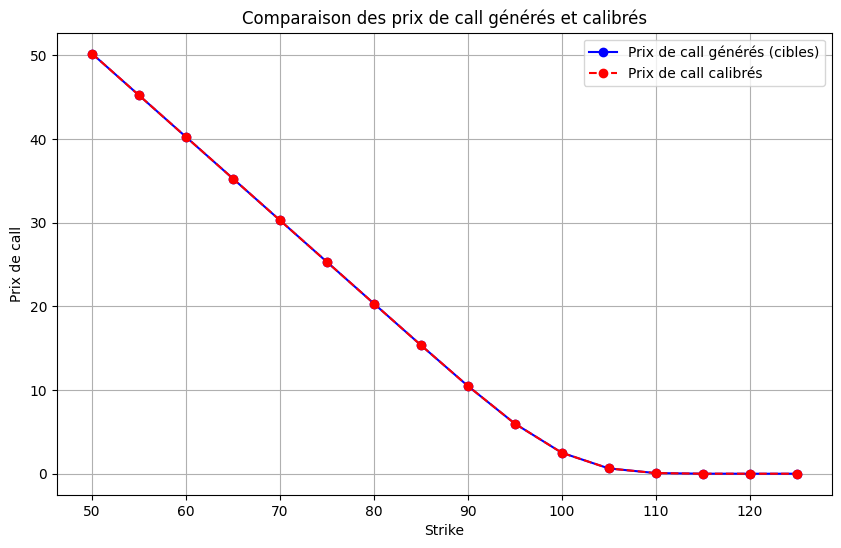

In [48]:
kappa_calibrated, rho_calibrated, volvol_calibrated, theta_calibrated, var0_calibrated = calibrated_params

# Calcul des prix de call avec les paramètres calibrés
call_prices_calibrated = [CallHestonCForm(Spot, Maturity, kappa_calibrated, rho_calibrated, volvol_calibrated, theta_calibrated, var0_calibrated, rate, div, strike) for strike in strikes]

# Ajout des prix calibrés au DataFrame
df['Call Price Calibrated'] = call_prices_calibrated

# Tracé des données
plt.figure(figsize=(10, 6))
plt.plot(df['Strike'], df['Call Price'], 'bo-', label='Prix de call générés (cibles)')
plt.plot(df['Strike'], df['Call Price Calibrated'], 'ro--', label='Prix de call calibrés')
plt.xlabel('Strike')
plt.ylabel('Prix de call')
plt.title('Comparaison des prix de call générés et calibrés')
plt.legend()
plt.grid()
plt.show()

### Calibrage sur prix données réel